# Video Game Sales Analysis: Which Genres Win in Which Region?

**Business question.** A game publisher with a limited budget wants to know which genres to prioritize in each region: North America, Europe, Japan, and the rest of the world.

**Sub-questions**
1. Which genres are the biggest markets in each region?
2. Which genres perform best *per title*, not just in total?
3. How different are regional tastes?
4. How concentrated are sales among publishers?

**Data.** `vgsales.csv`: 16,598 game titles released between 1980 and 2020, with sales per region in **millions of units** (not revenue). It appears to be the widely used Kaggle "Video Game Sales" dataset.

**Tools.** Python, pandas, NumPy, Matplotlib.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('charts', exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 100,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.alpha': 0.3,
    'axes.axisbelow': True,
})

REGIONS = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
LABELS = {'NA_Sales': 'North America', 'EU_Sales': 'Europe',
          'JP_Sales': 'Japan', 'Other_Sales': 'Other'}
COLORS = {'NA_Sales': '#2563eb', 'EU_Sales': '#0d9488',
          'JP_Sales': '#e11d48', 'Other_Sales': '#9ca3af'}

df = pd.read_csv('data/vgsales.csv')
print('Rows, columns:', df.shape)
display(df.head())

Rows, columns: (16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## 1. Data quality check

In [2]:
missing = df.isna().sum()
display(missing[missing > 0].to_frame('missing_values'))

print('Full duplicate rows (ignoring Rank):', df.drop(columns='Rank').duplicated().sum())
print('Release years covered:', int(df['Year'].min()), 'to', int(df['Year'].max()))
print()
print('Titles per release year (last years):')
print(df['Year'].value_counts().sort_index().loc[2014:].to_string())

,missing_values
Year,271
Publisher,58


Full duplicate rows (ignoring Rank): 1
Release years covered: 1980 to 2020

Titles per release year (last years):
Year
2014.0    582
2015.0    614
2016.0    344
2017.0      3
2020.0      1


**Cleaning decisions**
- **271 titles have no release year (1.6%).** I keep them for genre, region and publisher analysis and exclude them only from the yearly trend.
- **58 titles have no publisher.** Labeled `Unknown`.
- **1 exact duplicate row** (ignoring `Rank`) is removed.
- **2017 to 2020 contain only 4 titles, and 2016 looks incomplete** (344 titles vs 614 in 2015). The trend therefore uses 1995 to 2015 only.
- `Global_Sales` matches the sum of the four regions (checked below), so I treat the columns as consistent.

In [3]:
df = df.drop_duplicates(subset=df.columns.drop('Rank')).copy()
df['Publisher'] = df['Publisher'].fillna('Unknown')
print('Rows after cleaning:', len(df))

gap = (df[REGIONS].sum(axis=1) - df['Global_Sales']).abs().max()
print('Largest gap between Global_Sales and the sum of regions (millions):', round(gap, 2))

Rows after cleaning: 16597
Largest gap between Global_Sales and the sum of regions (millions): 0.02


## 2. Market size: total sales by genre and region

Total units show where the volume is.

,North America,Europe,Japan,Other,Global_Sales
Genre,,,,,
Action,877.8,525.0,160.0,187.4,1751.2
Sports,683.4,376.8,135.4,135.0,1330.9
Shooter,582.6,313.3,38.3,102.7,1037.4
Role-Playing,327.3,188.1,352.3,59.6,927.4
Platform,447.0,201.6,130.8,51.6,831.4
Misc,410.2,216.0,107.8,75.3,810.0
Racing,359.4,238.4,56.7,77.3,732.0
Fighting,223.6,101.3,87.4,36.7,448.9
Simulation,183.3,113.4,63.7,31.5,392.2


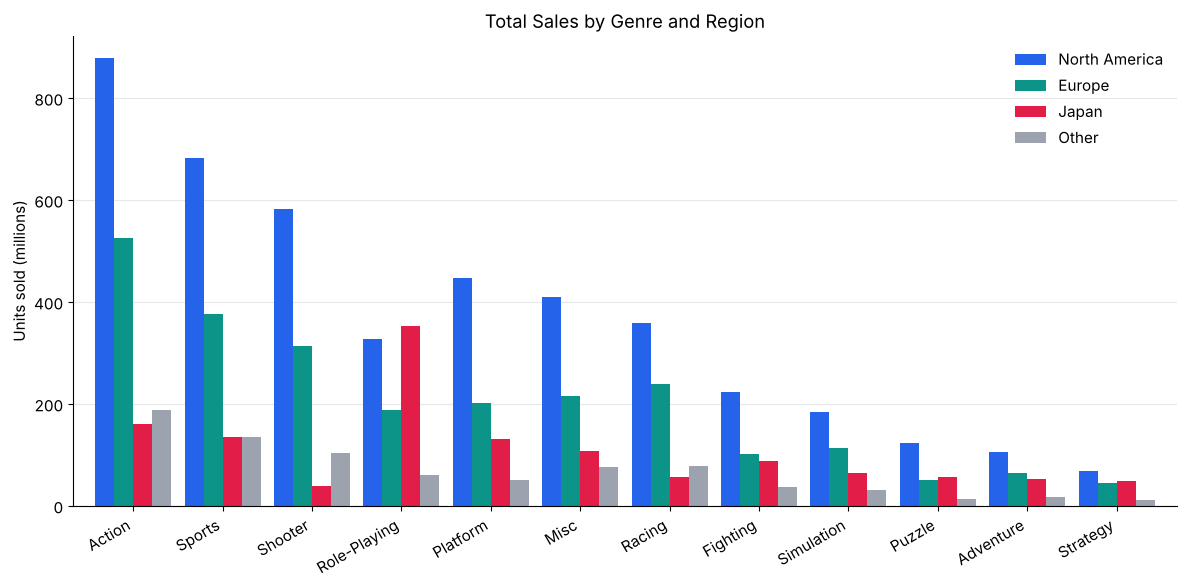

In [4]:
totals = (df.groupby('Genre')[REGIONS + ['Global_Sales']]
            .sum()
            .sort_values('Global_Sales', ascending=False))
display(totals.round(1).rename(columns=LABELS))

fig, ax = plt.subplots(figsize=(12, 6))
totals[REGIONS].plot(kind='bar', ax=ax, color=[COLORS[r] for r in REGIONS], width=0.85)
ax.grid(axis='x', visible=False)
ax.set_title('Total Sales by Genre and Region')
ax.set_ylabel('Units sold (millions)')
ax.set_xlabel('')
ax.legend([LABELS[r] for r in REGIONS], frameon=False)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('charts/01_total_sales_by_genre_region.png', dpi=150)
plt.show()

**Finding.** Action is the largest genre in North America, Europe and the Other regions, with Sports second in all three. Japan is the exception: Role-Playing is its biggest genre, at more than twice Action's volume there.

## 3. Typical performance per title

Totals favor genres with many releases. Action has the most titles, so a large total does not mean each title sells well. This section compares the **mean** (pulled up by blockbusters) and the **median** (a typical title).

,titles,mean,median
Genre,,,
Platform,886,0.938,0.280
Shooter,1309,0.792,0.230
Role-Playing,1488,0.623,0.185
Racing,1249,0.586,0.190
Sports,2346,0.567,0.220
Fighting,848,0.529,0.210
Action,3316,0.528,0.190
Misc,1739,0.466,0.160
Simulation,867,0.452,0.160


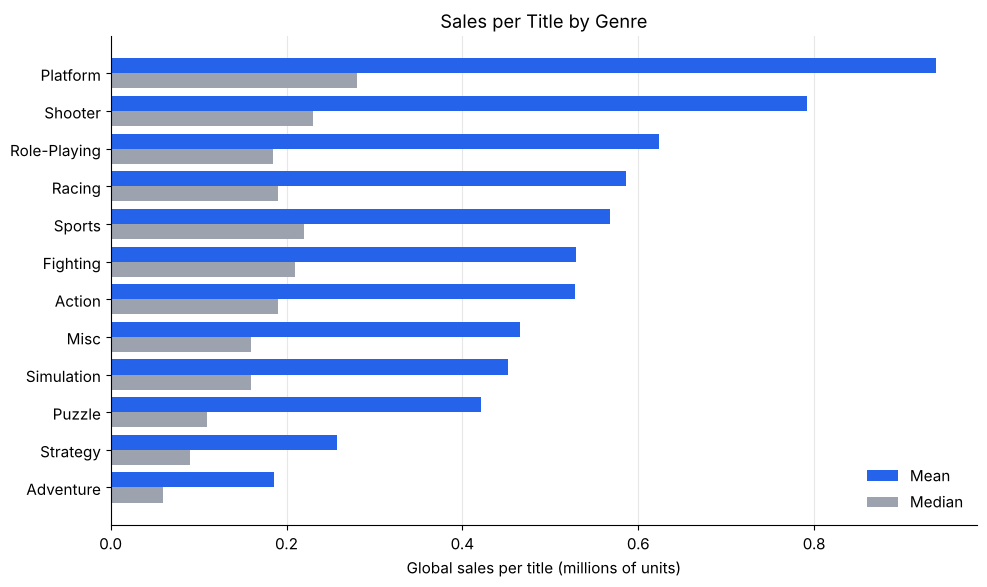

In [5]:
per_title = (df.groupby('Genre')['Global_Sales']
               .agg(titles='count', mean='mean', median='median')
               .sort_values('mean', ascending=False))
display(per_title.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(per_title))
ax.barh(y - 0.2, per_title['mean'], height=0.4, color='#2563eb', label='Mean')
ax.barh(y + 0.2, per_title['median'], height=0.4, color='#9ca3af', label='Median')
ax.set_yticks(y)
ax.set_yticklabels(per_title.index)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.grid(axis='x')
ax.set_xlabel('Global sales per title (millions of units)')
ax.set_title('Sales per Title by Genre')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('charts/02_sales_per_title_by_genre.png', dpi=150)
plt.show()

**Finding.** Platform (mean 0.94M, median 0.28M) and Shooter (0.79M, 0.23M) perform best per title. Action ranks only 7th by mean despite the largest total, so its volume comes from releasing many titles. In every genre the mean is roughly 2.5 to 4 times the median, which means a few hits lift the average. For a typical title, the median is the more honest number.

## 4. Regional taste: genre share of each region's sales

,North America,Europe,Japan,Other
Genre,,,,
Action,20.0,21.6,12.4,23.5
Sports,15.6,15.5,10.5,16.9
Shooter,13.3,12.9,3.0,12.9
Role-Playing,7.5,7.7,27.3,7.5
Platform,10.2,8.3,10.1,6.5
Misc,9.3,8.9,8.3,9.4
Racing,8.2,9.8,4.4,9.7
Fighting,5.1,4.2,6.8,4.6
Simulation,4.2,4.7,4.9,4.0


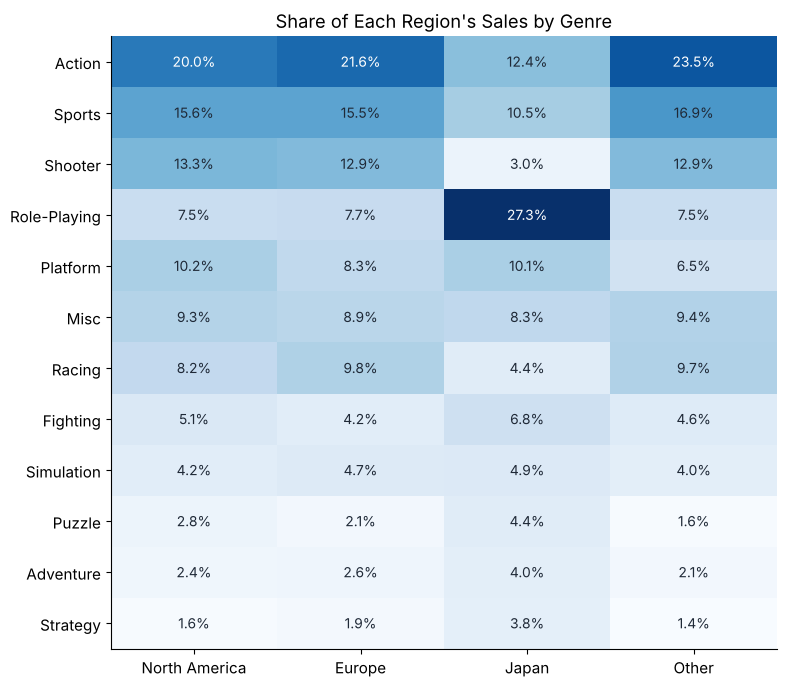

In [6]:
share = totals[REGIONS].div(totals[REGIONS].sum()) * 100
display(share.round(1).rename(columns=LABELS))

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(share.values, cmap='Blues', aspect='auto')
ax.grid(False)
ax.set_xticks(range(len(REGIONS)))
ax.set_xticklabels([LABELS[r] for r in REGIONS])
ax.set_yticks(range(len(share)))
ax.set_yticklabels(share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iat[i, j]
        ax.text(j, i, f'{v:.1f}%', ha='center', va='center',
                color='white' if v > 18 else '#1f2937', fontsize=10)
ax.set_title("Share of Each Region's Sales by Genre")
plt.tight_layout()
plt.savefig('charts/03_genre_share_by_region.png', dpi=150)
plt.show()

**Finding.** Japan has a clearly different taste. Role-Playing makes up 27.3% of Japanese sales versus about 7.5% in the other regions, while Shooter is only 3.0% in Japan versus about 13% elsewhere. North America, Europe and the Other regions look alike: Action is 20% to 24%, Sports 15% to 17%, Shooter about 13%.

## 5. Industry trend by release year (1995 to 2015)

,units,titles
Year,,
2008,678.9,1428
2009,667.3,1431
2007,611.1,1202
2010,600.4,1259
2006,521.0,1008


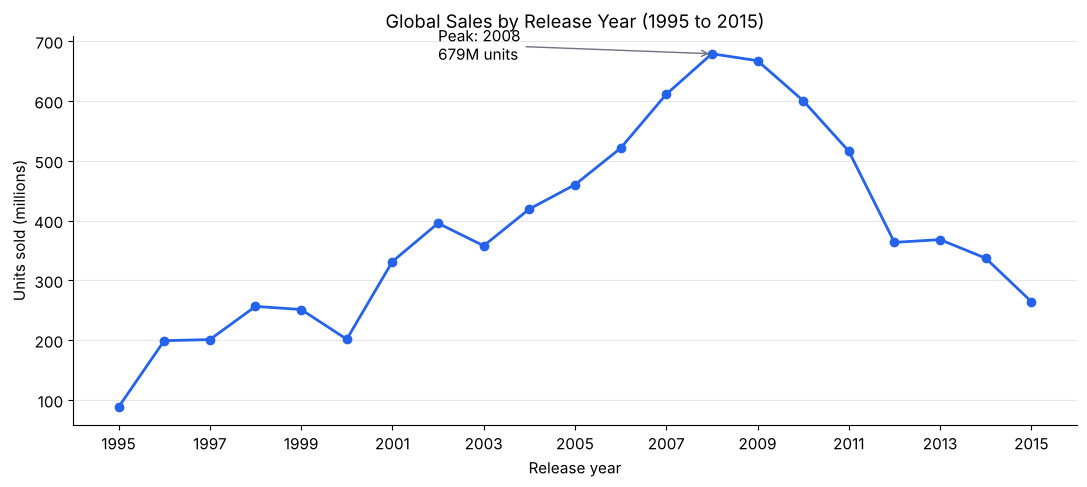

In [7]:
yearly = (df.dropna(subset=['Year'])
            .assign(Year=lambda d: d['Year'].astype(int))
            .query('1995 <= Year <= 2015')
            .groupby('Year')['Global_Sales']
            .agg(units='sum', titles='count'))
display(yearly.sort_values('units', ascending=False).head(5).round(1))

peak = int(yearly['units'].idxmax())
peak_units = yearly.loc[peak, 'units']

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(yearly.index, yearly['units'], color='#2563eb', marker='o', linewidth=2)
ax.annotate(f'Peak: {peak}\n{peak_units:.0f}M units', xy=(peak, peak_units),
            xytext=(peak - 6, peak_units - 10),
            arrowprops=dict(arrowstyle='->', color='#6b7280'))
ax.set_title('Global Sales by Release Year (1995 to 2015)')
ax.set_xlabel('Release year')
ax.set_ylabel('Units sold (millions)')
ax.set_xticks(range(1995, 2016, 2))
plt.tight_layout()
plt.savefig('charts/04_global_sales_by_year.png', dpi=150)
plt.show()

**Finding.** Sales peak with titles released in 2008 and fall afterwards. I read this as a pattern within this dataset, not as proof that the industry shrank: the data may not capture every sales channel (for example digital sales), and the last years are thinner.

## 6. Publisher concentration

,Region,Publisher,Share of region sales (%)
0,North America,Nintendo,18.6
1,North America,Electronic Arts,13.5
2,North America,Activision,9.8
3,Europe,Nintendo,17.2
4,Europe,Electronic Arts,15.3
5,Europe,Activision,8.9
6,Japan,Nintendo,35.3
7,Japan,Namco Bandai Games,9.8
8,Japan,Konami Digital Entertainment,7.1
9,Other,Electronic Arts,16.3


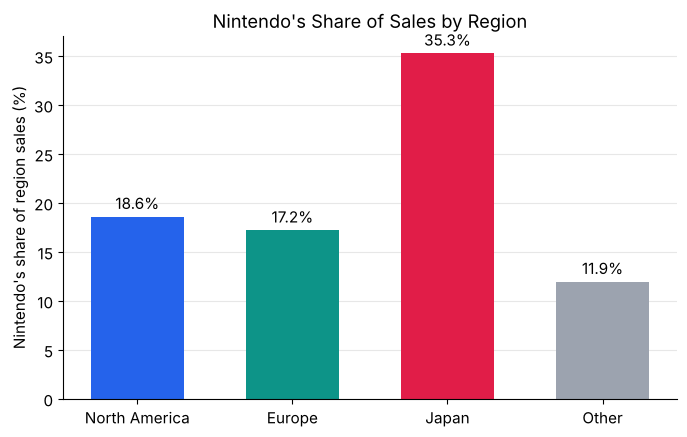

In [8]:
by_pub = df.groupby('Publisher')[REGIONS].sum()

rows = []
for r in REGIONS:
    top = (by_pub[r].sort_values(ascending=False).head(3) / df[r].sum() * 100).round(1)
    rows.append(pd.DataFrame({'Region': LABELS[r],
                              'Publisher': top.index,
                              'Share of region sales (%)': top.values}))
display(pd.concat(rows, ignore_index=True))

nintendo = by_pub.loc['Nintendo'] / df[REGIONS].sum() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar([LABELS[r] for r in REGIONS], nintendo.values,
       color=[COLORS[r] for r in REGIONS], width=0.6)
for i, v in enumerate(nintendo.values):
    ax.text(i, v + 0.8, f'{v:.1f}%', ha='center')
ax.set_ylabel("Nintendo's share of region sales (%)")
ax.set_title("Nintendo's Share of Sales by Region")
plt.tight_layout()
plt.savefig('charts/05_nintendo_share_by_region.png', dpi=150)
plt.show()

**Finding.** Nintendo is the top publisher in North America, Europe and Japan, and its share in Japan (35.3%) is roughly double its share in North America and Europe. In the Other regions, Electronic Arts leads (16.3%).

## 7. Recommendations

- **Japan:** lead with Role-Playing. It is the largest genre there by a wide margin, and Shooter is a weak bet (3.0% of sales).
- **North America and Europe:** Action and Sports are the biggest markets, so they suit a publisher able to release many titles. For a tight budget, Shooter and Platform give stronger sales per title.
- **Low priority for volume:** Strategy and Adventure sit near the bottom of the totals in every region and have the lowest sales per title.
- **Plan a different mix for Japan** rather than reusing the Western release plan.

## Limitations

- Sales are **units, not revenue**. There are no prices, costs or profit figures.
- Per-title averages depend on which titles are in the dataset and on how many titles each genre releases.
- Regional taste also reflects platforms and publishers (for example Nintendo hardware), not genre alone.
- The dataset thins out after 2015, so recent years are not covered well.
- The analysis is descriptive. No statistical tests were run, so differences are patterns, not proven effects.